# VAE on MNIST with a 2D latent space

A variational autoencoder (VAE) has two parts:
- the **encoder** turns an image $x$ into a small Gaussian over a code $z$, $q(z \mid x)$;
- the **decoder** turns a code back into pixel probabilities, $p(x \mid z)$.

Training balances good reconstructions against keeping the codes close to the prior $p(z) = \mathcal N(0, I)$. With a 2D code we can draw the whole latent space.

Import libraries

In [27]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from torch.distributions.normal import Normal
from torchvision import datasets

Define constants

In [28]:
torch.manual_seed(0)

LATENT_DIM = 2
BATCH = 128
EPOCHS = 20
LR = 1e-3

Select device

In [29]:
cuda_available = torch.cuda.is_available()
mps_available = torch.backends.mps.is_available()
device = os.environ.get("DEVICE") or ("cuda" if cuda_available  else "mps" if mps_available  else "cpu")
print("device:", device)

device: mps


Create directories

In [30]:
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

## Data

MNIST images are flattened to 784 pixel values in $[0, 1]$. The whole dataset fits in memory, so we keep it on the device and batch it ourselves (faster than a `DataLoader`).

In [31]:
train_set = datasets.MNIST("data", train=True, download=True)
test_set = datasets.MNIST("data", train=False, download=True)

X_train = train_set.data.float().div(255).view(-1, 784).to(device)
X_test = test_set.data.float().div(255).view(-1, 784).to(device)
y_test = test_set.targets


def batches(X, shuffle):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), BATCH):
        yield X[idx[i:i + BATCH]]


print(X_train.shape, X_test.shape)

torch.Size([60000, 784]) torch.Size([10000, 784])


## Model

Taken from the [PyTorch VAE example](https://github.com/pytorch/examples/blob/main/vae/main.py), with a 2D latent space instead of 20D.
- **Reparameterisation:** sample $z = \mu + \sigma \cdot \varepsilon$ with $\varepsilon \sim \mathcal N(0, I)$, so gradients can flow through $\mu$ and $\sigma$.
- **Loss** (per image) = reconstruction error (binary cross-entropy, as each pixel is treated as on/off) + KL divergence, which pulls $q(z \mid x)$ towards $\mathcal N(0, I)$.

In [32]:
class VAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.fc1 = nn.Linear(784, 400)
        self.fc21 = nn.Linear(400, latent_dim)   # mean of q(z|x)
        self.fc22 = nn.Linear(400, latent_dim)   # log-variance of q(z|x)
        self.fc3 = nn.Linear(latent_dim, 400)
        self.fc4 = nn.Linear(400, 784)

    def encode(self, x):
        h = F.relu(self.fc1(x))
        return self.fc21(h), self.fc22(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)

    def decode(self, z):
        return torch.sigmoid(self.fc4(F.relu(self.fc3(z))))   # pixel probabilities of p(x|z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterize(mu, logvar)), mu, logvar


def loss_function(recon_x, x, mu, logvar):
    bce = F.binary_cross_entropy(recon_x, x, reduction="sum")
    kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return bce + kld

## Training

Adam for 20 epochs (a 2D code needs a few more than the example's 10). Losses are averaged per image.

epoch  1  train  189.8  test  170.2
epoch  2  train  167.0  test  164.3
epoch  3  train  163.1  test  161.7
epoch  4  train  160.8  test  159.9
epoch  5  train  159.1  test  158.4
epoch  6  train  157.8  test  157.3
epoch  7  train  156.7  test  156.5
epoch  8  train  155.8  test  155.4
epoch  9  train  155.0  test  154.9
epoch 10  train  154.4  test  154.3
epoch 11  train  153.7  test  153.8
epoch 12  train  153.3  test  153.9
epoch 13  train  152.8  test  153.3
epoch 14  train  152.4  test  152.9
epoch 15  train  151.9  test  152.6
epoch 16  train  151.6  test  152.7
epoch 17  train  151.2  test  151.9
epoch 18  train  150.9  test  151.7
epoch 19  train  150.6  test  151.9
epoch 20  train  150.3  test  151.4


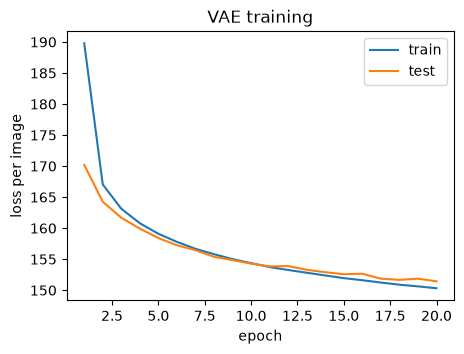

In [33]:
model = VAE().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
history = {"train": [], "test": []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    total = 0.0
    for x in batches(X_train, shuffle=True):
        recon, mu, logvar = model(x)
        loss = loss_function(recon, x, mu, logvar)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item()
    history["train"].append(total / len(X_train))

    model.eval()
    total = 0.0
    with torch.no_grad():
        for x in batches(X_test, shuffle=False):
            recon, mu, logvar = model(x)
            total += loss_function(recon, x, mu, logvar).item()
    history["test"].append(total / len(X_test))
    print(f"epoch {epoch:2d}  train {history['train'][-1]:6.1f}  test {history['test'][-1]:6.1f}")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(range(1, EPOCHS + 1), history["train"], label="train")
ax.plot(range(1, EPOCHS + 1), history["test"], label="test")
ax.set(xlabel="epoch", ylabel="loss per image", title="VAE training")
ax.legend()
plt.show()

## Latent space

Each test image is placed at its encoded mean $\mu$, coloured by its digit.

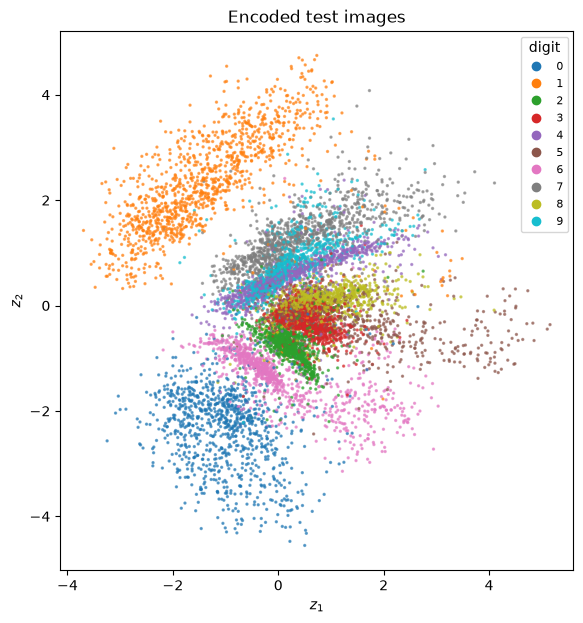

In [34]:
with torch.no_grad():
    mu_test, _ = model.encode(X_test)
mu_test = mu_test.cpu()


def plot_latent(ax):
    ax.scatter(mu_test[:, 0], mu_test[:, 1], c=y_test, cmap="tab10", vmin=-0.5, vmax=9.5, s=2, alpha=0.6)
    handles = [plt.Line2D([], [], marker="o", ls="", color=plt.cm.tab10(d), label=str(d)) for d in range(10)]
    ax.legend(handles=handles, title="digit", loc="upper right", fontsize=8)
    ax.set(xlabel=r"$z_1$", ylabel=r"$z_2$", aspect="equal")


fig, ax = plt.subplots(figsize=(7, 7))
plot_latent(ax)
ax.set_title("Encoded test images")
fig.savefig(FIG_DIR / "vae_latent.png", dpi=150, bbox_inches="tight")
plt.show()

Digits form clusters, and similar-looking digits overlap (e.g. 4 and 9, or 3, 5 and 8). The cloud stays centred around 0, because the KL term pulls codes towards $\mathcal N(0, I)$.

## Decoding a grid of codes: $p(x \mid z)$

We take $k \times k$ evenly spaced values in $(0, 1)$ and push them through the inverse Gaussian CDF (`Normal.icdf`). Each grid cell then covers an equal share of the prior's probability: points are packed near the centre, where $p(z)$ has most mass. We stop at 0.05 and 0.95 because the icdf of 0 and 1 is $\pm\infty$.

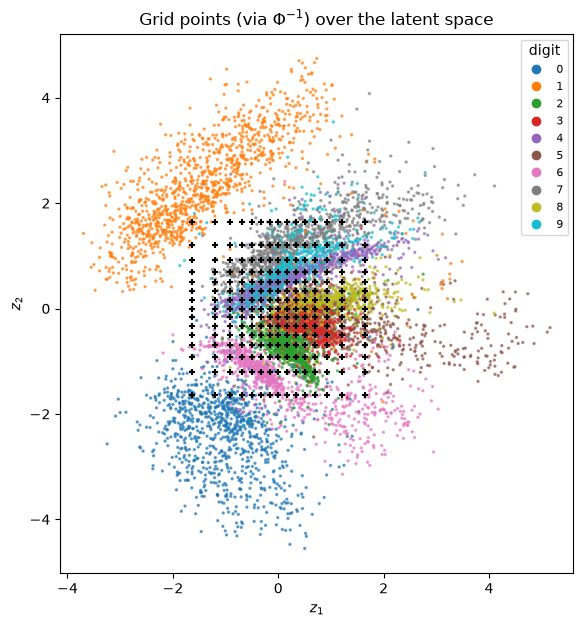

In [35]:
K = 15
u = torch.linspace(0.05, 0.95, K)
z_vals = Normal(0.0, 1.0).icdf(u)
Z1, Z2 = torch.meshgrid(z_vals, z_vals.flip(0), indexing="xy")   # top row = largest z2
grid_z = torch.stack([Z1.ravel(), Z2.ravel()], dim=1)

fig, ax = plt.subplots(figsize=(7, 7))
plot_latent(ax)
ax.scatter(grid_z[:, 0], grid_z[:, 1], c="k", marker="+", s=25, label="grid")
ax.set_title(r"Grid points (via $\Phi^{-1}$) over the latent space")
plt.show()

For each grid point we plot the decoder output: the pixel probabilities of $p(x \mid z)$, i.e. the average image for that code. The layout matches the plot above (right = larger $z_1$, up = larger $z_2$).

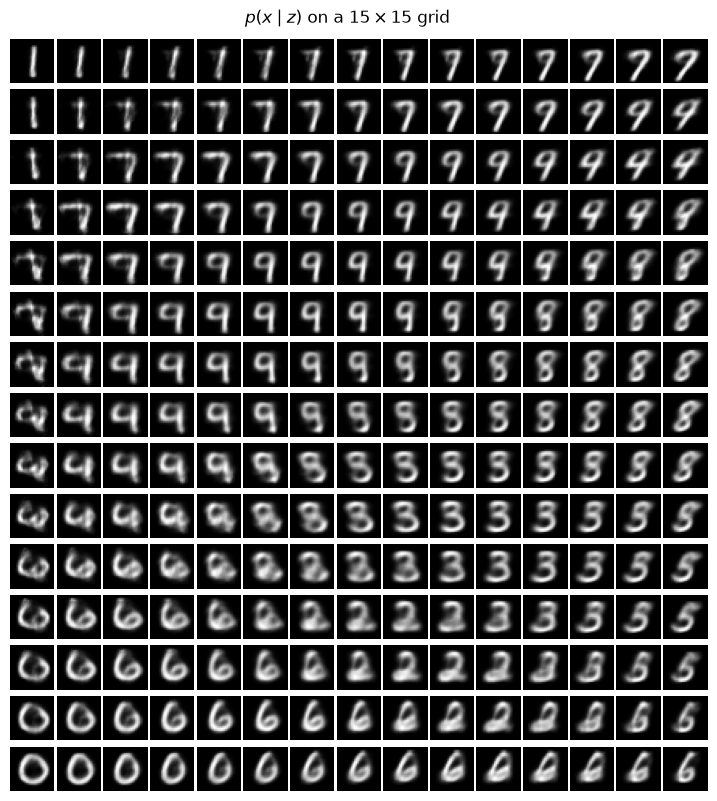

In [36]:
with torch.no_grad():
    imgs = model.decode(grid_z.to(device)).cpu().view(K, K, 28, 28)

fig, axes = plt.subplots(K, K, figsize=(9, 9))
for i in range(K):
    for j in range(K):
        axes[i, j].imshow(imgs[i, j], cmap="gray")
        axes[i, j].axis("off")
fig.suptitle(r"$p(x \mid z)$ on a $%d \times %d$ grid" % (K, K))
fig.subplots_adjust(wspace=0.05, hspace=0.05, top=0.95)
fig.savefig(FIG_DIR / "vae_grid.png", dpi=150, bbox_inches="tight")
plt.show()

Moving across the grid, the digits morph smoothly into each other, following the clusters in the latent plot. Almost every code decodes to a plausible digit and the blurry ones lie between clusters.